# Data Preprocessing

In [1]:
import pandas as pd
import numpy as np

In [3]:
data = pd.read_csv("day_1km-melbourne.csv").dropna(how="all").reset_index(drop=True)
#this dataset is 1000m resolution with:
#latitude: -27.96327996
#longitude: 151.6188731
#taken from ECOSTRESS dataset - website is

In [5]:
df = data.copy()
df["Date"] = pd.to_datetime(df["Date"])

# Drop the rows where the temperature is 0
df = df[df["MOD11A1_061_LST_Day_1km"] != 0]

# Drop 29 Feb so every year has at most 365 days
df = df[~((df["Date"].dt.month == 2) & (df["Date"].dt.day == 29))]

# Day number 1-365: in leap years, move days after Feb back by 1
after_feb_leap = df["Date"].dt.is_leap_year & (df["Date"].dt.month > 2)

new_df = pd.DataFrame({
    "Year": df["Date"].dt.year,
    "Day": df["Date"].dt.dayofyear - after_feb_leap.astype(int),
    "LST_K": df["MOD11A1_061_LST_Day_1km"],
}).reset_index(drop=True)

C:\Users\nadun\AppData\Local\Temp\ipykernel_14880\2733486668.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Date"] = pd.to_datetime(df["Date"])


In [7]:
new_df

,Year,Day,LST_K
0,2000,57,303.82
1,2000,58,298.88
2,2000,60,303.76
3,2000,61,307.06
4,2000,63,296.14
...,...,...,...
4232,2026,309,288.54
4233,2026,310,284.46
4234,2026,312,292.74
4235,2026,314,295.16


In [9]:
all_days = set(range(1, 366))            # check if there are missing days between 1-365
present = set(new_df["Day"].unique())

missing_days = sorted(all_days - present)
print(f"Days with no data in any year: {missing_days if missing_days else 'none'}")

Days with no data in any year: none


Which is good, which means we have some data from every day of year.

# Testing models for temperature

To decide between Linear, Quadratic or Harmonic

In [14]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error, r2_score

df = new_df.copy()
df["Yr"] = df["Year"] - 2000                      # centred year
df["sin1"] = np.sin(2 * np.pi * df["Day"] / 365)  # annual cycle
df["cos1"] = np.cos(2 * np.pi * df["Day"] / 365)
df["sin2"] = np.sin(4 * np.pi * df["Day"] / 365)  # half-year harmonic (allows a lopsided season)
df["cos2"] = np.cos(4 * np.pi * df["Day"] / 365)

# Time-based split: train on the past, test on recent years
train = df[df["Year"] <= 2021]
test  = df[df["Year"] >= 2022]

models = {
    "Linear":    "LST_K ~ Yr + Day",
    "Quadratic": "LST_K ~ Yr + I(Yr**2) + Day + I(Day**2)",
    "Harmonic":  "LST_K ~ Yr + sin1 + cos1 + sin2 + cos2",
}

results, fits = [], {}
for name, formula in models.items():
    fit = smf.ols(formula, data=train).fit()
    pred = fit.predict(test)
    fits[name] = fit
    results.append({
        "Model": name,
        "Train R²": fit.rsquared,
        "Test R²": r2_score(test["LST_K"], pred),
        "Test RMSE (K)": np.sqrt(mean_squared_error(test["LST_K"], pred)),
        "AIC": fit.aic,
        "BIC": fit.bic,
    })

print(pd.DataFrame(results).round(3))

       Model  Train R²  Test R²  Test RMSE (K)        AIC        BIC
0     Linear     0.039   -0.117          9.948  26527.770  26546.268
1  Quadratic     0.738    0.670          5.407  21953.956  21984.785
2   Harmonic     0.797    0.679          5.331  21068.882  21105.878


**Clearly the Harmonic model is the best model that represents the data points. Best R-squared value and lowest AIC and BIC**

# Plotting Models and Fit

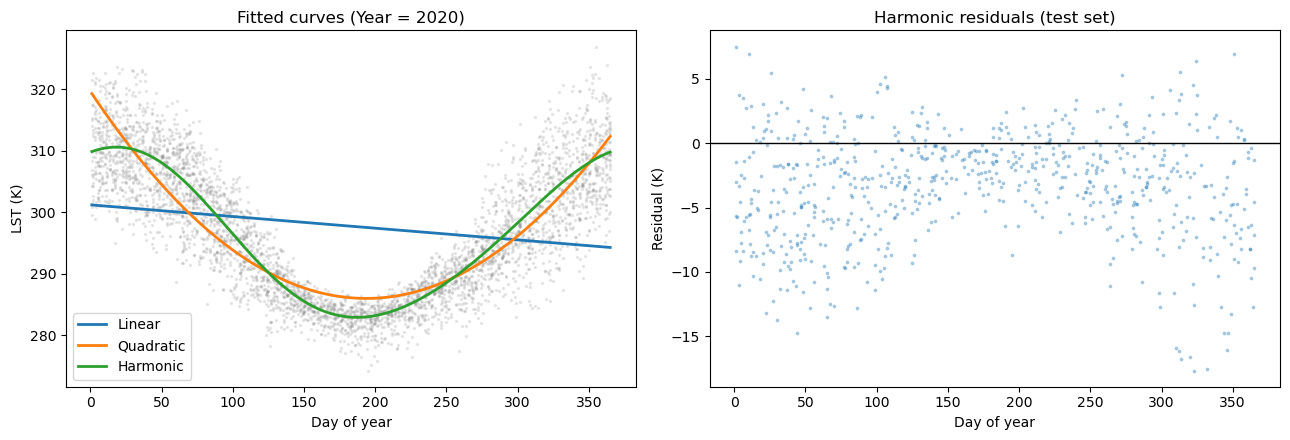

                            OLS Regression Results                            
Dep. Variable:                  LST_K   R-squared:                       0.797
Model:                            OLS   Adj. R-squared:                  0.796
Method:                 Least Squares   F-statistic:                     2753.
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:16:44   Log-Likelihood:                -10528.
No. Observations:                3519   AIC:                         2.107e+04
Df Residuals:                    3513   BIC:                         2.111e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    296.2763      0.161   1839.565      0.0

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Fitted seasonal curve for one year vs the data
days = pd.DataFrame({"Day": np.arange(1, 366), "Yr": 20})
days["sin1"] = np.sin(2*np.pi*days.Day/365); days["cos1"] = np.cos(2*np.pi*days.Day/365)
days["sin2"] = np.sin(4*np.pi*days.Day/365); days["cos2"] = np.cos(4*np.pi*days.Day/365)

axes[0].scatter(df["Day"], df["LST_K"], s=2, alpha=0.15, color="grey")
for name, fit in fits.items():
    axes[0].plot(days["Day"], fit.predict(days), label=name, lw=2)
axes[0].set(xlabel="Day of year", ylabel="LST (K)", title="Fitted curves (Year = 2020)")
axes[0].legend()

# Residuals by day for the best model; a pattern here means the model misses something
best = "Harmonic"
resid = test["LST_K"] - fits[best].predict(test)
axes[1].scatter(test["Day"], resid, s=3, alpha=0.3)
axes[1].axhline(0, color="k", lw=1)
axes[1].set(xlabel="Day of year", ylabel="Residual (K)", title=f"{best} residuals (test set)")

plt.tight_layout(); plt.show()

print(fits[best].summary())   # check the Yr coefficient and its p-value

## Finding equations of Models for 40% interquartile range of data points

In [21]:
# for lines 20% above and below central temperature model line

import statsmodels.formula.api as smf

formula = "LST_K ~ Yr + sin1 + cos1 + sin2 + cos2"
quantiles = [0.3, 0.7]

qfits = {q: smf.quantreg(formula, data=train).fit(q=q) for q in quantiles}

# Print each as an equation in the same form as predict_lst
for q, fit in qfits.items():
    p = fit.params
    print(f"\nq = {q}:")
    print(f"LST = {p['Intercept']:.3f} {p['Yr']:+.4f}*(year-2000) "
          f"{p['sin1']:+.3f}*sin(t) {p['cos1']:+.3f}*cos(t) "
          f"{p['sin2']:+.3f}*sin(2t) {p['cos2']:+.3f}*cos(2t)")

# Check coverage on the test set: should be close to 20% / 20%
below = (test["LST_K"] < qfits[0.3].predict(test)).mean()
above = (test["LST_K"] > qfits[0.7].predict(test)).mean()
print(f"\nTest set: {below:.1%} below lower line, {above:.1%} above upper line")


q = 0.3:
LST = 294.216 -0.0159*(year-2000) +3.005*sin(t) +11.962*cos(t) +1.339*sin(2t) +0.348*cos(2t)

q = 0.7:
LST = 298.636 -0.0149*(year-2000) +3.156*sin(t) +14.623*cos(t) +0.952*sin(2t) +0.099*cos(2t)

Test set: 60.0% below lower line, 7.0% above upper line


## Finding equations of Models for maximum and minimum

In [24]:
# getting the minimum and maximum temperature lines
import numpy as np
from scipy.optimize import linprog

cols = ["Yr", "sin1", "cos1", "sin2", "cos2"]
X = np.column_stack([np.ones(len(df)), df[cols].to_numpy()])   # intercept + terms
y = df["LST_K"].to_numpy()

# Max curve: minimise total gap (sum of Xb - y) subject to Xb >= y for every point
res_max = linprog(c=X.sum(axis=0), A_ub=-X, b_ub=-y, bounds=(None, None), method="highs")

# Min curve: maximise total (sum of Xb) subject to Xb <= y for every point
res_min = linprog(c=-X.sum(axis=0), A_ub=X, b_ub=y, bounds=(None, None), method="highs")

names = ["Intercept"] + cols
def show(label, b):
    p = dict(zip(names, b))
    print(f"{label}: LST = {p['Intercept']:.3f} {p['Yr']:+.4f}*(year-2000) "
          f"{p['sin1']:+.3f}*sin(t) {p['cos1']:+.3f}*cos(t) "
          f"{p['sin2']:+.3f}*sin(2t) {p['cos2']:+.3f}*cos(2t)")

show("Max", res_max.x)
show("Min", res_min.x)

# Sanity check: should print True, True
print((X @ res_max.x >= y - 1e-6).all(), (X @ res_min.x <= y + 1e-6).all())

Max: LST = 308.213 -0.0559*(year-2000) +2.104*sin(t) +19.579*cos(t) -1.158*sin(2t) -0.533*cos(2t)
Min: LST = 282.976 -0.0641*(year-2000) +2.227*sin(t) +7.972*cos(t) +0.991*sin(2t) +0.926*cos(2t)
True True


In [26]:
axes[0].fill_between(days["Day"], qfits[0.3].predict(days), qfits[0.7].predict(days),
                     alpha=0.25, label="20–80% band")

In [28]:
df

,Year,Day,LST_K,Yr,sin1,cos1,sin2,cos2
0,2000,57,303.82,0,0.831171,0.556017,0.924291,-0.381689
1,2000,58,298.88,0,0.840618,0.541628,0.910605,-0.413279
2,2000,60,303.76,0,0.858764,0.512371,0.880012,-0.474951
3,2000,61,307.06,0,0.867456,0.497513,0.863142,-0.504961
4,2000,63,296.14,0,0.884068,0.467359,0.826354,-0.563151
...,...,...,...,...,...,...,...,...
4232,2026,309,288.54,26,-0.821477,0.570242,-0.936881,-0.349647
4233,2026,310,284.46,26,-0.811539,0.584298,-0.948362,-0.317191
4234,2026,312,292.74,26,-0.790946,0.611886,-0.967938,-0.251190
4235,2026,314,295.16,26,-0.769415,0.638749,-0.982927,-0.183998


In [30]:
fit_hac = smf.ols("LST_K ~ Yr + sin1 + cos1 + sin2 + cos2", data=train).fit(
    cov_type="HAC", cov_kwds={"maxlags": 10})
print(fit_hac.summary())

                            OLS Regression Results                            
Dep. Variable:                  LST_K   R-squared:                       0.797
Model:                            OLS   Adj. R-squared:                  0.796
Method:                 Least Squares   F-statistic:                     934.3
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:16:57   Log-Likelihood:                -10528.
No. Observations:                3519   AIC:                         2.107e+04
Df Residuals:                    3513   BIC:                         2.111e+04
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    296.2763      0.330    899.119      0.0

In [43]:
Year=2027
Day=5

In [45]:
def predict_lst(year, day):
    t = 2 * np.pi * day / 365
    return (296.2763 - 0.0091 * (year - 2000)
            + 2.9884 * np.sin(t)   + 13.3994 * np.cos(t)
            + 1.0061 * np.sin(2*t) + 0.2837 * np.cos(2*t))

In [47]:
predict_lst(Year,Day) - 273.15

36.93913994641349

      mean  count
Year             
2022 -2.74    123
2023 -2.65    149
2024 -3.18    150
2025 -3.06    148
2026 -5.15    148


<Axes: title={'center': 'Annual mean LST'}, xlabel='Year'>

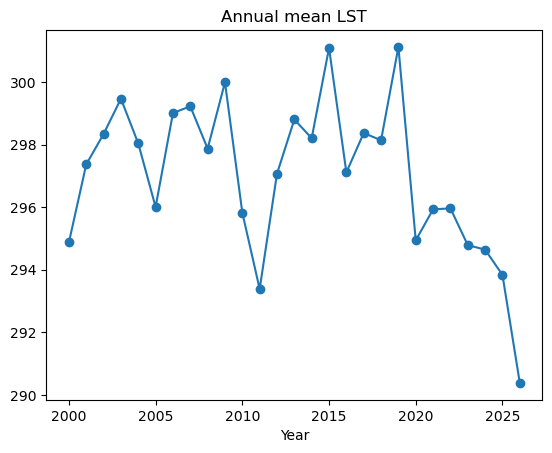

In [49]:
# 1. Bias per test year: is it stable or growing?
resid = test["LST_K"] - fits["Harmonic"].predict(test)
print(resid.groupby(test["Year"]).agg(["mean", "count"]).round(2))

# 2. Annual mean LST over the whole record: look for a step around 2020-22
new_df.groupby("Year")["LST_K"].mean().plot(marker="o", title="Annual mean LST")

Quite significantly colder readings in recent years from 2021 onwards, any satellite measuring or device error?